# HJNC 자부두 환적 타임라인 정리 및 총 소요시간 분석

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
DGT_DGT_CSV_PATH = './data/HJNC_HJNC_2025.csv'
df = pd.read_csv(DGT_DGT_CSV_PATH)

In [68]:
df

,컨테이너번호,선사코드,적/공,Size/Type,화물종류,중량(kg),Seal No,BL No,양하항,적하항,...,양하모선명,양하모선항차,적하모선명,적하모선항차,선내위치,야드 장치시간,온샤시 시간,경과료 Free Date,냉동료 Free Date,반출예정일
0,AMFU8667185,SML,F,40/GE(4500),G,26950.0,seal1:11994500,PHX5A5110700,KRKAN,KRPUS,...,SM PORTLAND,SMPL-006/2025,SM NINGBO,SMNB-007/2025,10-09-82,2025-05-11 18:12:55,2025-05-31 15:08:56,2025-05-22 23:59:59,NaN,NaN
1,AXIU1350376,SML,F,40/GE(4510),G,26318.0,seal1:0020158,PHX5A4854700,KRKAN,KRPUS,...,SM QINGDAO,SMQT-005/2025,SM YANTIAN,SMYT-005/2025,42-03-88,2025-05-02 01:52:19,2025-05-05 04:29:04,2025-05-13 23:59:59,NaN,NaN
2,AXIU4223734,SML,F,4210,G,22620.0,seal1:SML221951,SZP5J5662500,USPDX,KRPUS,...,SM SEOUL,SMSE-005/2025,SM SHANGHAI,SMSH-012/2025,22-02-12,2025-09-08 01:31:40,2025-09-12 12:57:30,2025-09-19 23:59:59,NaN,NaN
3,BEAU4507198,YML,F,40/GE(45G0),G,4580.0,seal1:UL1268624,YMJAE125365026,CNSHA,KRPUS,...,ONE CONTINUITY,OOCN-004/2025,HMM DUBLIN,HODU-002/2025,06-08-80,2025-09-27 16:00:29,2025-10-03 01:27:46,2025-10-12 23:59:59,NaN,NaN
4,BEAU4549233,HLC,F,40/GE(4500),G,13994.0,seal1:HLK0749815,HLCUNG12412VEIY0,CAVA5,KRPUS,...,TSINGTAO EXPRESS,TSXX-001/2025,YM TIPTOP,YIPT-001/2025,46-00-82,2025-02-11 17:27:03,2025-02-15 23:18:19,2025-02-22 23:59:59,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1485,TXGU8526371,HMM,F,40/GE(4500),G,22410.0,seal1:24H1603152,HANM12415700,USHOU,KRPUS,...,CONTI CRYSTAL,OCNC-001/2025,ONE MODERN,OOMD-004/2025,30-08-08,2025-11-18 17:09:09,2025-11-22 10:47:36,2025-11-29 23:59:59,NaN,NaN
1486,TXGU8676622,ONE,F,40/GE(4500),G,20500.0,seal1:ONO35193,HNLF00888800,SGSIN,KRPUS,...,NOBILITY,ONBD-007/2025,YM WELLBEING,YMEG-003/2025,34-18-76,2025-10-08 03:18:44,2025-10-16 21:38:28,NaN,NaN,NaN
1487,UACU5394368,HLC,F,40/GE(4500),G,30346.0,seal1:182601,HLCUBSC2412CABK6,CNYTN,KRPUS,...,AIN SNAN EXPRESS,SNAX-001/2025,AL ZUBARA,ZUBX-001/2025,18-11-12,2025-02-16 02:06:58,2025-02-22 10:12:10,2025-02-27 23:59:59,NaN,NaN
1488,UACU5680042,HLC,F,40/GE(4500),G,17009.0,seal1:HLK1283433,HLCUTA12501DHGD0,MYTPP,KRPUS,...,LUDWIGSHAFEN EXPRESS,LWXG-001/2025,BANGKOK EXPRESS,BGKX-001/2025,10-16-72,2025-02-04 01:27:15,2025-02-06 18:02:44,2025-02-15 23:59:59,NaN,NaN


In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 31 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   컨테이너번호         1490 non-null   str    
 1   선사코드           1490 non-null   str    
 2   적/공            1490 non-null   str    
 3   Size/Type      1490 non-null   str    
 4   화물종류           1490 non-null   str    
 5   중량(kg)         1490 non-null   float64
 6   Seal No        1490 non-null   str    
 7   BL No          1444 non-null   str    
 8   양하항            1490 non-null   str    
 9   적하항            1490 non-null   str    
 10  야드위치           1490 non-null   str    
 11  반입방식           1490 non-null   str    
 12  반입시간           1490 non-null   str    
 13  반출방식           1490 non-null   str    
 14  반출시간           1490 non-null   str    
 15  반입차량번호         0 non-null      float64
 16  반출차량번호         0 non-null      float64
 17  손상여부           3 non-null      str    
 18  IMDG           6 no

In [70]:
df.isna().sum()

컨테이너번호              0
선사코드                0
적/공                 0
Size/Type           0
화물종류                0
중량(kg)              0
Seal No             0
BL No              46
양하항                 0
적하항                 0
야드위치                0
반입방식                0
반입시간                0
반출방식                0
반출시간                0
반입차량번호           1490
반출차량번호           1490
손상여부             1487
IMDG             1484
UNNO             1484
온도               1482
양하모선명               0
양하모선항차              0
적하모선명               0
적하모선항차              0
선내위치                0
야드 장치시간             0
온샤시 시간              0
경과료 Free Date      12
냉동료 Free Date    1490
반출예정일            1490
dtype: int64

In [71]:
pd.DataFrame({
    '자료형' : df.dtypes.astype('str'),
    '비결측수' : df.notna().sum(),
    '결측수' : df.isna().sum(),
    '결측률(%)' : df.isna().mean() * 100,
    '고유값 수' : df.nunique(dropna=True) # 결측치는 빼고 구하겠다.
})

,자료형,비결측수,결측수,결측률(%),고유값 수
컨테이너번호,str,1490,0,0.000000,1490
선사코드,str,1490,0,0.000000,6
적/공,str,1490,0,0.000000,1
Size/Type,str,1490,0,0.000000,21
화물종류,str,1490,0,0.000000,3
중량(kg),float64,1490,0,0.000000,1316
Seal No,str,1490,0,0.000000,1487
BL No,str,1444,46,3.087248,1303
양하항,str,1490,0,0.000000,66
적하항,str,1490,0,0.000000,1


In [72]:
df.columns

Index(['컨테이너번호', '선사코드', '적/공', 'Size/Type', '화물종류', '중량(kg)', 'Seal No',
       'BL No', '양하항', '적하항', '야드위치', '반입방식', '반입시간', '반출방식', '반출시간', '반입차량번호',
       '반출차량번호', '손상여부', 'IMDG', 'UNNO', '온도', '양하모선명', '양하모선항차', '적하모선명',
       '적하모선항차', '선내위치', '야드 장치시간', '온샤시 시간', '경과료 Free Date', '냉동료 Free Date',
       '반출예정일'],
      dtype='str')

In [73]:
# 공컨테이너는 환적 과정에서의 병목을 파악하기에 부적절하므로 제외하고 적컨으로만 분석 진행
full_con = df[df['적/공'] == 'F']
print(full_con)

           컨테이너번호 선사코드 적/공    Size/Type 화물종류   중량(kg)           Seal No  \
0     AMFU8667185  SML   F  40/GE(4500)    G  26950.0    seal1:11994500   
1     AXIU1350376  SML   F  40/GE(4510)    G  26318.0     seal1:0020158   
2     AXIU4223734  SML   F         4210    G  22620.0   seal1:SML221951   
3     BEAU4507198  YML   F  40/GE(45G0)    G   4580.0   seal1:UL1268624   
4     BEAU4549233  HLC   F  40/GE(4500)    G  13994.0  seal1:HLK0749815   
...           ...  ...  ..          ...  ...      ...               ...   
1485  TXGU8526371  HMM   F  40/GE(4500)    G  22410.0  seal1:24H1603152   
1486  TXGU8676622  ONE   F  40/GE(4500)    G  20500.0    seal1:ONO35193   
1487  UACU5394368  HLC   F  40/GE(4500)    G  30346.0      seal1:182601   
1488  UACU5680042  HLC   F  40/GE(4500)    G  17009.0  seal1:HLK1283433   
1489  UACU5867352  HLC   F  40/GE(4500)    G  24280.0     seal1:3730768   

                 BL No    양하항    적하항  ...                 양하모선명  \
0         PHX5A5110700  KRKAN  K

In [74]:
# 분석에 필요 없는 컬럼 모두 제거
df_time = full_con[['컨테이너번호', '반입시간', '야드 장치시간', '온샤시 시간', '반출시간']].copy()
df_time

,컨테이너번호,반입시간,야드 장치시간,온샤시 시간,반출시간
0,AMFU8667185,2025-05-11 18:08:47,2025-05-11 18:12:55,2025-05-31 15:08:56,2025-05-31 15:17:33
1,AXIU1350376,2025-05-02 01:45:56,2025-05-02 01:52:19,2025-05-05 04:29:04,2025-05-05 04:34:34
2,AXIU4223734,2025-09-08 01:27:09,2025-09-08 01:31:40,2025-09-12 12:57:30,2025-09-12 13:06:59
3,BEAU4507198,2025-09-27 15:54:15,2025-09-27 16:00:29,2025-10-03 01:27:46,2025-10-03 01:36:22
4,BEAU4549233,2025-02-11 17:21:39,2025-02-11 17:27:03,2025-02-15 23:18:19,2025-02-15 23:30:07
...,...,...,...,...,...
1485,TXGU8526371,2025-11-18 17:03:02,2025-11-18 17:09:09,2025-11-22 10:47:36,2025-11-22 10:50:32
1486,TXGU8676622,2025-10-08 03:11:58,2025-10-08 03:18:44,2025-10-16 21:38:28,2025-10-16 21:44:20
1487,UACU5394368,2025-02-16 02:02:32,2025-02-16 02:06:58,2025-02-22 10:12:10,2025-02-22 10:17:10
1488,UACU5680042,2025-02-04 01:14:15,2025-02-04 01:27:15,2025-02-06 18:02:44,2025-02-06 18:30:01


In [75]:
# 계산을 위해 반입시간, 반출시간, 온샤시 시간, 야드 장치 시간 자료 형식 날짜로 변경
df_time['반입시간'] = pd.to_datetime(df_time['반입시간'])
df_time['반출시간'] = pd.to_datetime(df_time['반출시간'])
df_time['온샤시 시간'] = pd.to_datetime(df_time['온샤시 시간'])
df_time['야드 장치시간'] = pd.to_datetime(df_time['야드 장치시간'])

In [76]:
df_time.info()

<class 'pandas.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   컨테이너번호   1490 non-null   str           
 1   반입시간     1490 non-null   datetime64[us]
 2   야드 장치시간  1490 non-null   datetime64[us]
 3   온샤시 시간   1490 non-null   datetime64[us]
 4   반출시간     1490 non-null   datetime64[us]
dtypes: datetime64[us](4), str(1)
memory usage: 58.3 KB


In [77]:
# 반입시간과 반출시간 모두 2025년 1월 1일 ~ 2025년 12월 31일 안에 있는 데이터만 추출

start_date = '2025-01-01 00:00:00'
end_date = '2025-12-31 23:59:59'

filtered_df = df_time[
    (df_time['반입시간'] >= start_date) & (df_time['반입시간'] <= end_date) &
    (df_time['반출시간'] >= start_date) & (df_time['반출시간'] <= end_date)
]

filtered_df.shape

(1490, 5)

### 각 공정별 작업시간 구하기

In [79]:
# 공정A. 양하~장치 (야드 장치 시간 - 반입시간)
filtered_df['공정A(양하~장치)'] = filtered_df['야드 장치시간'] - filtered_df['반입시간']
print(filtered_df)

           컨테이너번호                반입시간             야드 장치시간              온샤시 시간  \
0     AMFU8667185 2025-05-11 18:08:47 2025-05-11 18:12:55 2025-05-31 15:08:56   
1     AXIU1350376 2025-05-02 01:45:56 2025-05-02 01:52:19 2025-05-05 04:29:04   
2     AXIU4223734 2025-09-08 01:27:09 2025-09-08 01:31:40 2025-09-12 12:57:30   
3     BEAU4507198 2025-09-27 15:54:15 2025-09-27 16:00:29 2025-10-03 01:27:46   
4     BEAU4549233 2025-02-11 17:21:39 2025-02-11 17:27:03 2025-02-15 23:18:19   
...           ...                 ...                 ...                 ...   
1485  TXGU8526371 2025-11-18 17:03:02 2025-11-18 17:09:09 2025-11-22 10:47:36   
1486  TXGU8676622 2025-10-08 03:11:58 2025-10-08 03:18:44 2025-10-16 21:38:28   
1487  UACU5394368 2025-02-16 02:02:32 2025-02-16 02:06:58 2025-02-22 10:12:10   
1488  UACU5680042 2025-02-04 01:14:15 2025-02-04 01:27:15 2025-02-06 18:02:44   
1489  UACU5867352 2025-03-31 15:51:36 2025-03-31 16:01:51 2025-04-13 18:12:58   

                    반출시간   

In [80]:
# 공정A의 평균 시간
mean_process_a = filtered_df['공정A(양하~장치)'].mean().floor('s')
print(mean_process_a)

0 days 00:06:34


In [81]:
# 공정B. 장치~온샤시 (온샤시 시간 - 야드 장치 시간)
filtered_df['공정B(장치~온샤시)'] = filtered_df['온샤시 시간'] - filtered_df['야드 장치시간']
print(filtered_df)

           컨테이너번호                반입시간             야드 장치시간              온샤시 시간  \
0     AMFU8667185 2025-05-11 18:08:47 2025-05-11 18:12:55 2025-05-31 15:08:56   
1     AXIU1350376 2025-05-02 01:45:56 2025-05-02 01:52:19 2025-05-05 04:29:04   
2     AXIU4223734 2025-09-08 01:27:09 2025-09-08 01:31:40 2025-09-12 12:57:30   
3     BEAU4507198 2025-09-27 15:54:15 2025-09-27 16:00:29 2025-10-03 01:27:46   
4     BEAU4549233 2025-02-11 17:21:39 2025-02-11 17:27:03 2025-02-15 23:18:19   
...           ...                 ...                 ...                 ...   
1485  TXGU8526371 2025-11-18 17:03:02 2025-11-18 17:09:09 2025-11-22 10:47:36   
1486  TXGU8676622 2025-10-08 03:11:58 2025-10-08 03:18:44 2025-10-16 21:38:28   
1487  UACU5394368 2025-02-16 02:02:32 2025-02-16 02:06:58 2025-02-22 10:12:10   
1488  UACU5680042 2025-02-04 01:14:15 2025-02-04 01:27:15 2025-02-06 18:02:44   
1489  UACU5867352 2025-03-31 15:51:36 2025-03-31 16:01:51 2025-04-13 18:12:58   

                    반출시간   

In [82]:
# 공정B 의 평균 시간
mean_process_b = filtered_df['공정B(장치~온샤시)'].mean().floor('s')
print(mean_process_b)

8 days 03:53:51


In [83]:
# 공정C. 온샤시~반출 (반출시간 - 온샤시 시간)
filtered_df['공정C(온샤시~반출)'] = filtered_df['반출시간'] - filtered_df['온샤시 시간']
print(filtered_df)

           컨테이너번호                반입시간             야드 장치시간              온샤시 시간  \
0     AMFU8667185 2025-05-11 18:08:47 2025-05-11 18:12:55 2025-05-31 15:08:56   
1     AXIU1350376 2025-05-02 01:45:56 2025-05-02 01:52:19 2025-05-05 04:29:04   
2     AXIU4223734 2025-09-08 01:27:09 2025-09-08 01:31:40 2025-09-12 12:57:30   
3     BEAU4507198 2025-09-27 15:54:15 2025-09-27 16:00:29 2025-10-03 01:27:46   
4     BEAU4549233 2025-02-11 17:21:39 2025-02-11 17:27:03 2025-02-15 23:18:19   
...           ...                 ...                 ...                 ...   
1485  TXGU8526371 2025-11-18 17:03:02 2025-11-18 17:09:09 2025-11-22 10:47:36   
1486  TXGU8676622 2025-10-08 03:11:58 2025-10-08 03:18:44 2025-10-16 21:38:28   
1487  UACU5394368 2025-02-16 02:02:32 2025-02-16 02:06:58 2025-02-22 10:12:10   
1488  UACU5680042 2025-02-04 01:14:15 2025-02-04 01:27:15 2025-02-06 18:02:44   
1489  UACU5867352 2025-03-31 15:51:36 2025-03-31 16:01:51 2025-04-13 18:12:58   

                    반출시간   

In [84]:
# 공정C 의 평균 시간
mean_process_c = filtered_df['공정C(온샤시~반출)'].mean().floor('s')
print(mean_process_c)

0 days 00:10:22


In [85]:
# 총 소요시간 구하기
filtered_df['총소요시간'] = (filtered_df['반출시간'] - filtered_df['반입시간']).dt.total_seconds() / 3600  # 시간 단위
# 만약 '분(minute)' 단위로 구하고 싶다면 아래 주석처럼 60으로 나누거나 .dt.total_seconds() / 60을 사용하세요
# df['총소요시간'] = (df['반출시간'] - df['반입시간']).dt.total_seconds() / 60  # 분 단위

print(filtered_df)

           컨테이너번호                반입시간             야드 장치시간              온샤시 시간  \
0     AMFU8667185 2025-05-11 18:08:47 2025-05-11 18:12:55 2025-05-31 15:08:56   
1     AXIU1350376 2025-05-02 01:45:56 2025-05-02 01:52:19 2025-05-05 04:29:04   
2     AXIU4223734 2025-09-08 01:27:09 2025-09-08 01:31:40 2025-09-12 12:57:30   
3     BEAU4507198 2025-09-27 15:54:15 2025-09-27 16:00:29 2025-10-03 01:27:46   
4     BEAU4549233 2025-02-11 17:21:39 2025-02-11 17:27:03 2025-02-15 23:18:19   
...           ...                 ...                 ...                 ...   
1485  TXGU8526371 2025-11-18 17:03:02 2025-11-18 17:09:09 2025-11-22 10:47:36   
1486  TXGU8676622 2025-10-08 03:11:58 2025-10-08 03:18:44 2025-10-16 21:38:28   
1487  UACU5394368 2025-02-16 02:02:32 2025-02-16 02:06:58 2025-02-22 10:12:10   
1488  UACU5680042 2025-02-04 01:14:15 2025-02-04 01:27:15 2025-02-06 18:02:44   
1489  UACU5867352 2025-03-31 15:51:36 2025-03-31 16:01:51 2025-04-13 18:12:58   

                    반출시간   

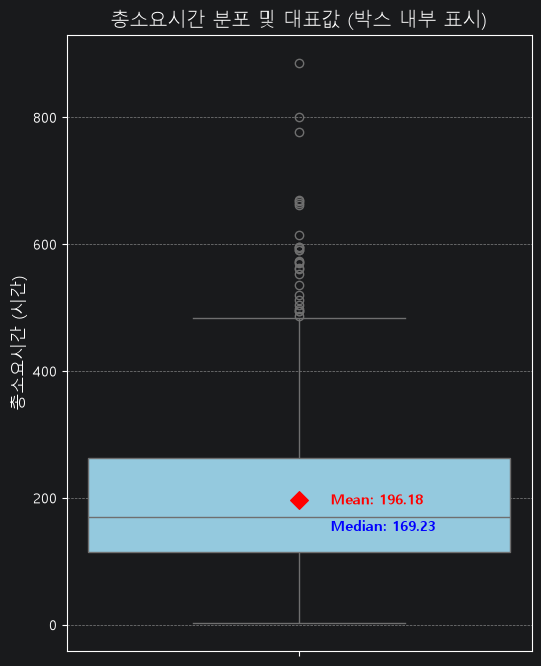

In [86]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 평균값과 중앙값 계산
mean_val = filtered_df['총소요시간'].mean()
median_val = filtered_df['총소요시간'].median()

# 2. 박스플롯 그리기
plt.figure(figsize=(6, 8))
ax = sns.boxplot(y=filtered_df['총소요시간'], color='skyblue', width=0.4)

# 3. 평균값 마커와 텍스트를 박스 내부(x=0 근처)로 배치
plt.scatter(0, mean_val, color='red', marker='D', s=80, zorder=5)
# x 좌표를 0.03 정도로 주어 박스 안쪽 왼편에 텍스트가 위치하도록 설정
plt.text(0.03, mean_val, f'Mean: {mean_val:.2f}', color='red', va='center', fontweight='bold', fontsize=10)

# 4. 중앙값 텍스트도 박스 내부 중앙선 근처에 배치
# 중앙값 선(median_val)보다 살짝 위나 아래로 여백을 주어 겹치지 않게 조절 가능합니다.
plt.text(0.03, median_val - 15, f'Median: {median_val:.2f}', color='blue', va='center', fontweight='bold', fontsize=10)

# 5. 그래프 꾸미기
plt.title('총소요시간 분포 및 대표값 (박스 내부 표시)', fontsize=14)
plt.ylabel('총소요시간 (시간)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

## 정리

공정A(양하 ~ 장치)의 평균 작업 시간 : 6분 34초

공정B(장치 ~ 온샤시)의 평균 작업 시간 : 8일 3시간 53분 51초

공정C(온샤시 ~ 반출)의 평균 작업 시간 : 10분 22초

총소요시간(시간) : 평균 196.18, 중앙값 169.23